# FMA Music Dataset analysis

### About the dataset

The **Free Music Archive (FMA)** is a public dataset of ~106 574 Creative-Commons audio tracks released by Defferrard et al. (2017), built to support music-information-retrieval research. Each track ships with metadata (artist, album, title, top-level genre, release date) and **518 pre-computed audio features** extracted via `librosa` (MFCC, chroma, spectral centroid / bandwidth / rolloff / contrast, RMSE, ZCR, tonnetz). The catalog is organised into three nested subsets — `small` (8 000 tracks, balanced across 8 top genres), `medium` (25 000), and `large` (the full 106 574) — plus a long-tail of tracks with no `set.subset` label. The audio itself is available as MP3s per subset (`fma_small` is ~7 GB); the analyses in this notebook only need the metadata + features archives, which `dataset.py` downloads automatically in the next cell.


## What we are analysing

**Section 1 — Per-decade PCA + k-means.** For each decade with enough tracks, we project the FMA audio-feature space to 2D via PCA and overlay k-means clusters (k chosen by elbow detection). The goal is to see how the geometry of the audio-feature space differs across decades.

**Section 2 — Title & genre exploration.** Four lexical / metadata views over the catalog:
- *2.1* how the share of each top genre evolves over time,
- *2.2* the most frequent words in song titles per decade (word clouds),
- *2.3* how often song titles repeat within a decade,
- *2.4* pairwise vocabulary overlap between top genres (Jaccard similarity).

**Section 3 — Genre-pair PCA centroid distances over 5y periods.** We fit one global PCA on standardized audio features, then for each 5y period compute the centroid of each top genre in PCA-2D. For every genre pair we measure the Euclidean distance between their centroids per period and track how that distance moves over time. The question: do genre pairs **converge or diverge** in audio-feature space as time progresses?

## 0. Download the FMA dataset

Run this cell once before anything else. `FMADataset()` fetches the FMA metadata archive and the `fma_small` audio archive into `./data/`, then unzips them. The class is **idempotent** — if the extracted folders already exist it logs a skip message and returns immediately, so re-running is safe and fast.

In [ ]:
from fma_analysis.dataset import FMADataset

FMADataset()

In [1]:
%matplotlib inline
import os
import logging

import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from fma_analysis import utils
from fma_analysis.decade_analysis import DecadeAnalyzer
from fma_analysis.visualizer import Visualizer
from fma_analysis import visualization
from fma_analysis.genre_pair_analysis import GenrePairAnalyzer, interesting_pairs

logging.basicConfig(level=logging.INFO, format='%(levelname)s %(name)s: %(message)s')

METADATA_DIR = 'data/fma_metadata'
tracks = utils.load(os.path.join(METADATA_DIR, 'tracks.csv'))
features = utils.load(os.path.join(METADATA_DIR, 'features.csv'))
print(f'tracks: {tracks.shape}, features: {features.shape}')

tracks: (106574, 52), features: (106574, 518)


## 1. Per-decade PCA + K-means (audio features)

For each decade with at least `min_samples=30` tracks, we run PCA on the standardized FMA feature set augmented with cross-feature derivations (`feature_engineering.get_cross_features`). K-means is fit on the 2D PCA coordinates and the optimal `k` is selected via elbow detection (`KneeLocator`).

In [3]:
decade_results = DecadeAnalyzer(tracks, features, min_samples=30).analyze_all()
print(f'Decades analyzed: {sorted(decade_results.keys())}')

Decades: 100%|██████████| 3/3 [00:01<00:00,  2.67it/s]

Decades analyzed: [1990, 2000, 2010]


### 1.1 Decade grid — PCA scatter + cluster overlays

Points colored by top genre; gray convex hulls outline k-means clusters; black `×` marks cluster centroids. Look at how the geometry of the audio-feature space changes across decades and whether genre separation strengthens or weakens.
**Findings**: Only three decades clear the `min_samples=30` bar — 1990s (n=87), 2000s (n=1251), 2010s (n=3972). Genres overlap heavily in PCA-2D and PC1+PC2 captures only ~20% of variance, so the visible cluster outlines don't cleanly separate by genre. The 1990s subplot is too sparse to read strongly.

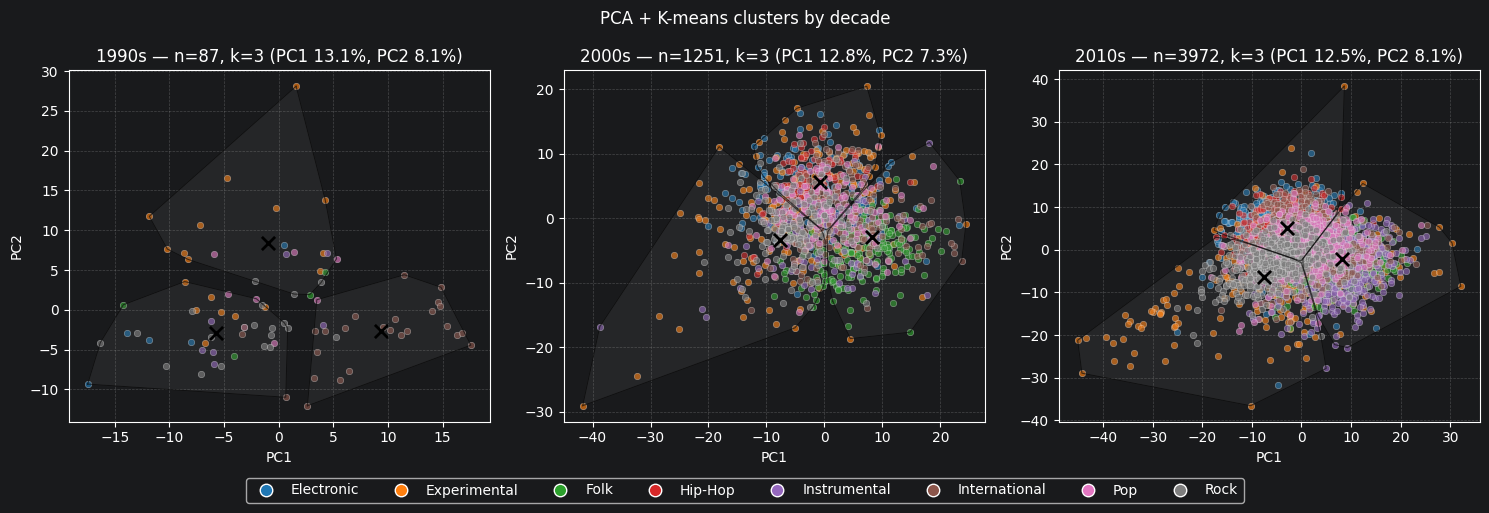

In [4]:
Visualizer.plot_decade_grid(decade_results)
plt.show()

### 1.2 Elbow curves per decade

Inertia vs `k` for `k ∈ {1..10}`. The red dashed line marks the elbow-selected `k`. A sharp kink means a strong cluster structure; a smooth curve means k-means is slicing a roughly uniform cloud.
**Findings**: All three elbow curves are smooth with no sharp kink, so `KneeLocator` returns no knee and every decade falls back to the hard-coded **k=3** default. The honest interpretation: the audio-feature cloud has no natural cluster structure at this projection — k-means is slicing a roughly continuous distribution.

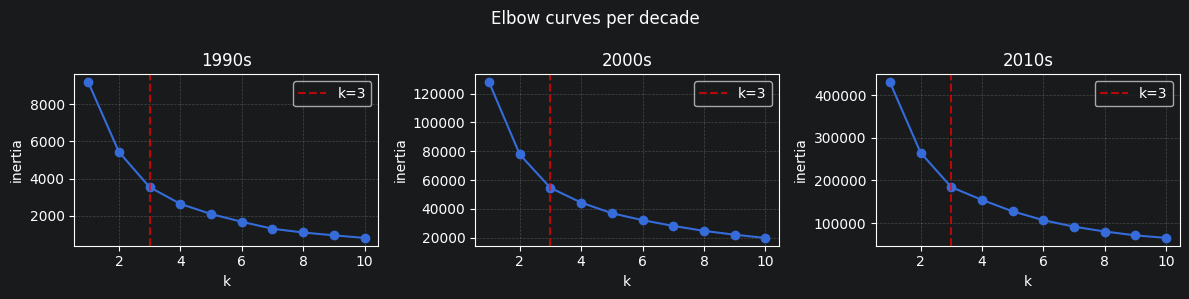

In [5]:
Visualizer.plot_elbow_grid(decade_results)
plt.show()

## 2. Title & genre exploration

Lexical and metadata analyses driven by `tracks.csv`. These do not use audio features — only the textual track metadata (titles, genres, release years).

In [6]:
viz = visualization.Visualizer()

INFO:dataset:Downloading FMA datasets
INFO:dataset:Unpacking FMA datasets
INFO:dataset:Skipping unzip, ./data/fma_metadata already exists.
INFO:dataset:Skipping unzip, ./data/fma_small already exists.
INFO:dataset:Finished unpacking FMA datasets


### 2.1 Genre trend over time

Share of each top genre across decades. Captures the shifting composition of the FMA catalog rather than a property of music itself — useful as a control when interpreting other trends.
**Findings**: The x-axis here is actually **year (2008–2017)**, not decade. Most genres ramp up through the early 2010s and peak around 2014–2016; the sharp drop in 2017 is a catalog artifact (incomplete final year of uploads), not a real popularity signal. Best read as a picture of FMA catalog growth, not of music popularity.

INFO:visualization:Loading CSV files...
INFO:visualization:Data loaded successfully.


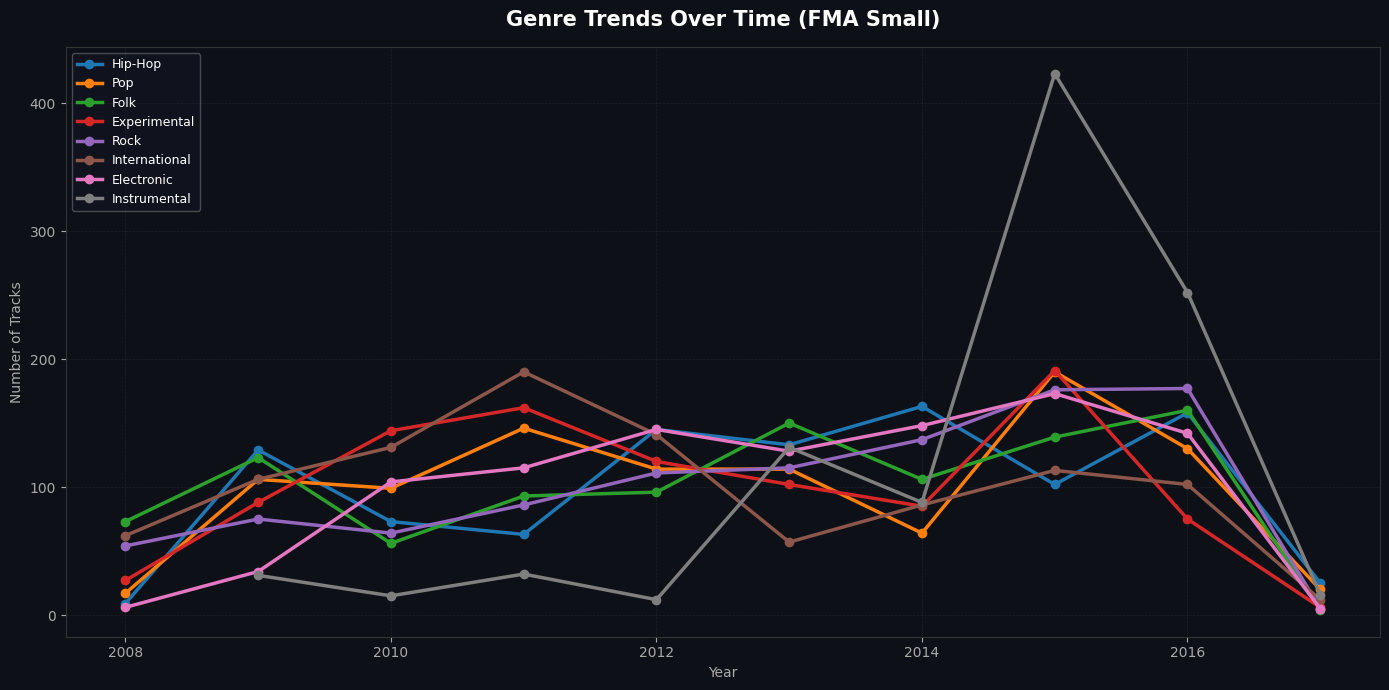

In [7]:
viz.plot_genre_trend(top_n=8)
plt.show()

### 2.2 Vocabulary by decade (song titles)

**Research question 1**: How has the vocabulary used in song titles changed across decades? The figure shows which words dominate titles per decade — a proxy for lexical drift in the catalog.
**Findings**: Both decades are dominated by **You / I / Me / Love** — emotion-and-pronoun vocabulary is universal across the catalog. The clearest difference is **Remix / Mix** appearing prominently in the 2010s but not the 2000s — a fingerprint of remix culture's rise. "Instrumental" is huge in both panels because many tracks are literally titled "Instrumental" or include that word.

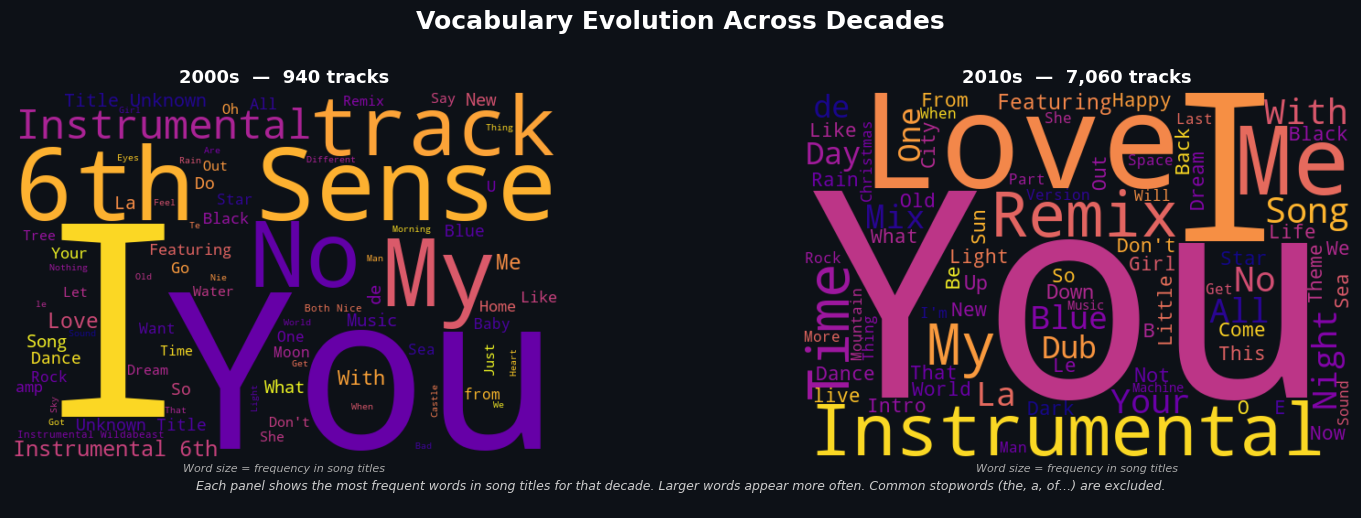

In [8]:
viz.plot_vocabulary_by_decade()
plt.show()

### 2.3 Title duplication over time

**Research question 2**: How frequently do song titles overlap? Rate of duplicate titles per decade — trends here reflect both naming conventions and catalog density.
**Findings**: Only two decades have enough data, and the duplicate rate **roughly doubled — 1.5% (2000s) → 2.6% (2010s)**. Likely a mix of more tracks per artist (more collision opportunities), the rise of remix/cover titles, and generic placeholders like "Untitled" or "Intro".

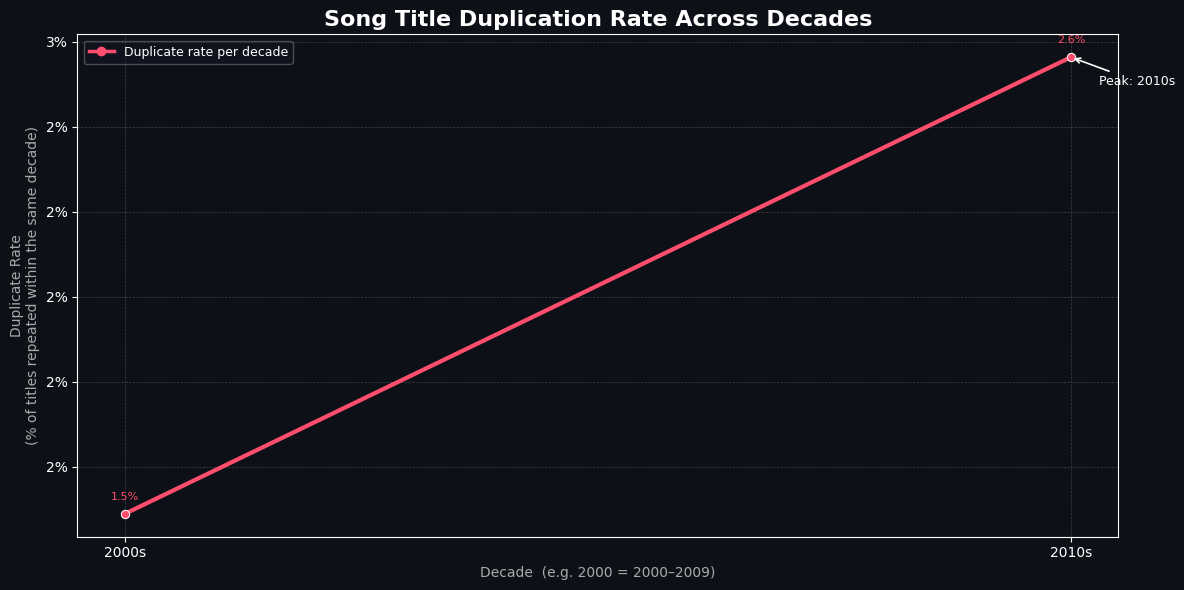

In [9]:
viz.plot_title_duplicate_rate()
plt.show()

### 2.4 Genre vocabulary overlap heatmap

**Research question 3**: How much overlap exists between genres in title vocabulary? Cell `(i, j)` is the share of genre *i*'s title vocabulary that also appears in genre *j*. Diagonal is self-overlap (=1).
**Findings (from the rendered heatmap)**:

_Note_: the plot's title shows the metric is **Jaccard similarity** (intersection / union of word sets), so the matrix is symmetric — read the framing above as approximate; the actual values are direction-agnostic.

- All off-diagonal values are **small (0.08–0.18)** — genres have largely distinct title vocabularies. Even the most-overlapping pair shares less than ~1 in 5 unique words.
- **Pop vs. Rock has the highest overlap (0.18)**, followed by Folk vs. Rock (0.17) and Folk vs. Pop (0.16). These three genres form a "Western popular music" cluster with the most shared vocabulary.
- **International is the most distinct genre** (~0.08 against every other genre). Almost certainly driven by non-English / non-Latin-script titles whose word sets barely intersect with English-language genres.
- **Hip-Hop also stands apart** (~0.13–0.15 to the others), consistent with its slang-heavy, more idiosyncratic lexicon.
- **Experimental sits in the middle** (~0.13–0.15) — not as integrated as the Pop/Rock/Folk trio, not as isolated as International.

**Takeaway**: title vocabularies are mostly idiomatic to their genre. The Pop/Rock/Folk cluster is the only group with detectable lexical convergence; International and Hip-Hop are the outliers in opposite ways (language barrier vs. slang vocabulary).

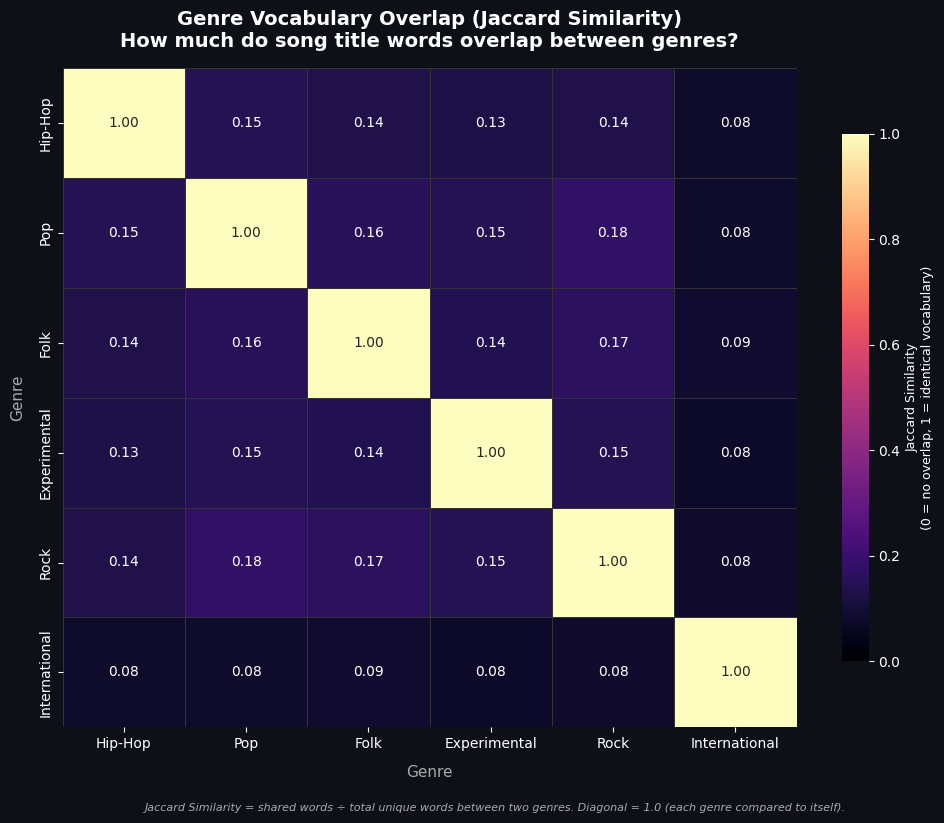

In [10]:
viz.plot_genre_overlap_heatmap(top_n=6)
plt.show()

## 3. Genre-pair PCA centroid distances over time

One global PCA is fit on all valid tracks (audio features + cross-feature derivations). Tracks are bucketed into 5y periods from 1980 to 2015. For each `(period, top_genre)` cell with ≥10 tracks, we compute the centroid in PCA-2D; for each pair we then compute the Euclidean distance between the two centroids per period.

Question: **are genre pairs converging or diverging over time?**

### Why so few periods actually have data

The original intention was to trace divergence/convergence across a much longer timespan — ideally back into the 1960s/70s, giving roughly **8–10 five-year periods** of observable change. In practice we only end up with **3 to 4 usable periods** (1995, 2000, 2005, 2010 — and 1995 is marginal even on the full catalog). Three things compound to produce this:

1. **FMA's release-date metadata is sparse.** Of 106 574 tracks in `tracks.csv`, ~57 000 (~53%) have no `album.date_released` value at all — they're filtered out before bucketing.
2. **What's left skews heavily post-2000.** The FMA was built primarily from Creative-Commons / independent releases uploaded during the 2000s–2010s; older mainstream catalog music is largely absent. So even the tracks *with* release dates concentrate in the 2000–2014 range.
3. **The `min_samples=10` per `(period, genre)` cell threshold then cuts the long tail.** A centroid built from <10 tracks is too noisy to compare, so cells below that bar are dropped (`NaN`). Pre-1995 cells almost never clear the threshold; even on `--subset large` only **1 pair each** has data in 1980 and 1985.

Concrete coverage (non-null pairs per period):

| subset | 1980 | 1985 | 1990 | 1995 | 2000 | 2005 | 2010 |
|---|---|---|---|---|---|---|---|
| `small` (8 genres, 28 pairs) | 0 | 0 | 0 | 3 | 15 | 28 | 28 |
| `large` (16 genres, 120 pairs) | 1 | 1 | 0 | 10 | 66 | 105 | 105 |

We deliberately keep the empty periods on the x-axis (rather than cropping) so the data sparsity is visible. If/when the same code is run against a dataset with denser pre-2000 release-date metadata (e.g. a MusicBrainz-linked catalog), the existing analysis fills in additional periods automatically.

In [2]:
pair_result = GenrePairAnalyzer(tracks, features, min_samples=10).analyze()
print(f'Tracks used: {len(pair_result.X_pca)}, genres: {pair_result.genres}, periods: {pair_result.period_starts}')

INFO:fma_analysis.genre_pair_analysis:Fitting global PCA on 4099 tracks (after period+feature filters)


INFO:fma_analysis.genre_pair_analysis:Computing centroids over 7 periods x 8 genres (min_samples=10 per cell)


Tracks used: 4099, genres: ['Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Rock'], periods: [1980, 1985, 1990, 1995, 2000, 2005, 2010]


### 3.1 Distance trends — small multiples by anchor genre

Eight subplots (one per top genre as anchor). Each subplot shows the distance from that anchor to each of the other seven genres across periods. Falling lines = the two genres are sounding more alike; rising lines = drifting apart.

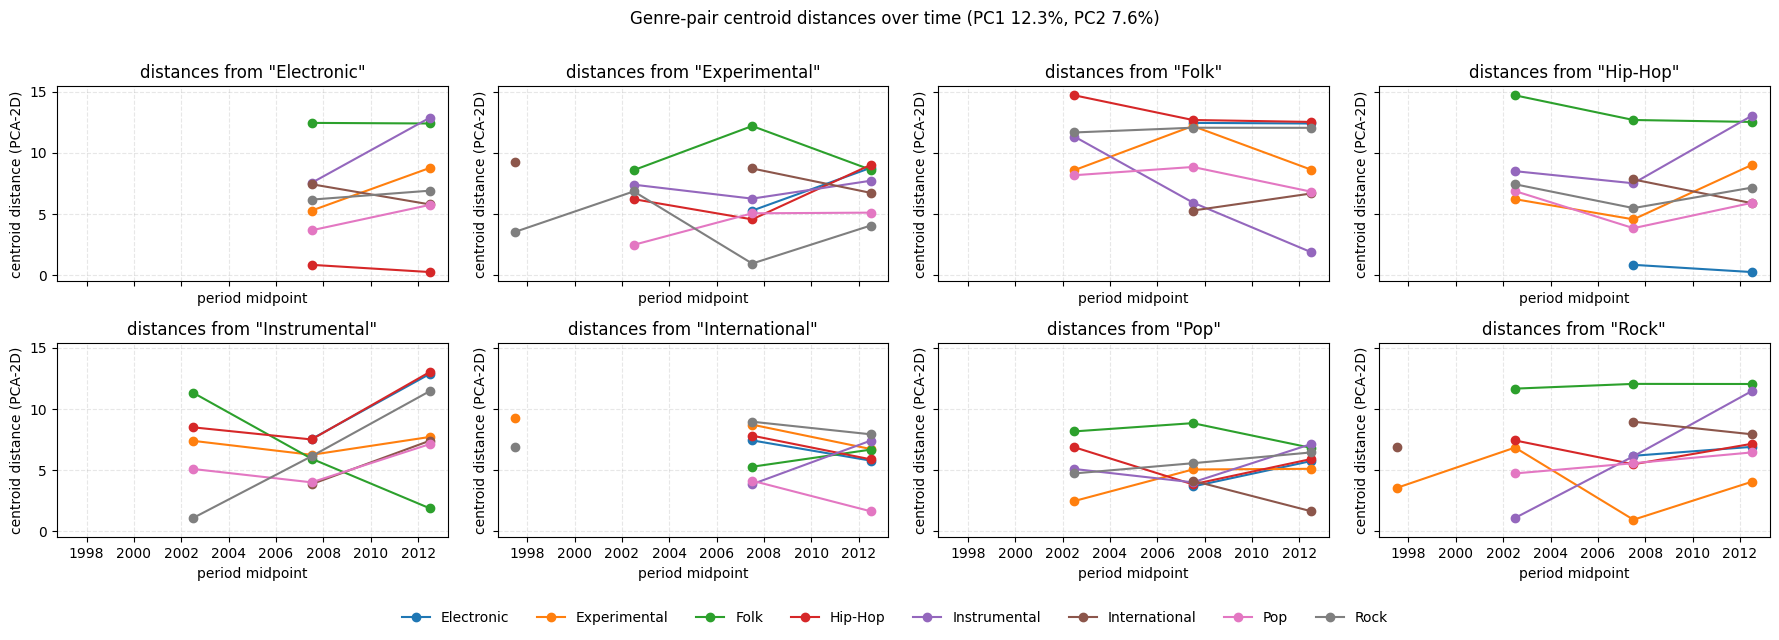

In [3]:
Visualizer.plot_pair_distance_trends(pair_result)
plt.show()

### 3.2 Per-pair time strip (interesting pairs)

Only the pairs whose centroid distance changed by ≥30% across available periods are shown. Each row is a pair; each column is a 5y period. Cells show both genres' points in shared PCA-2D coordinates with their centroids marked `×`. Look for the two clouds physically moving closer or apart across columns.

13 of 28 pairs qualify as interesting


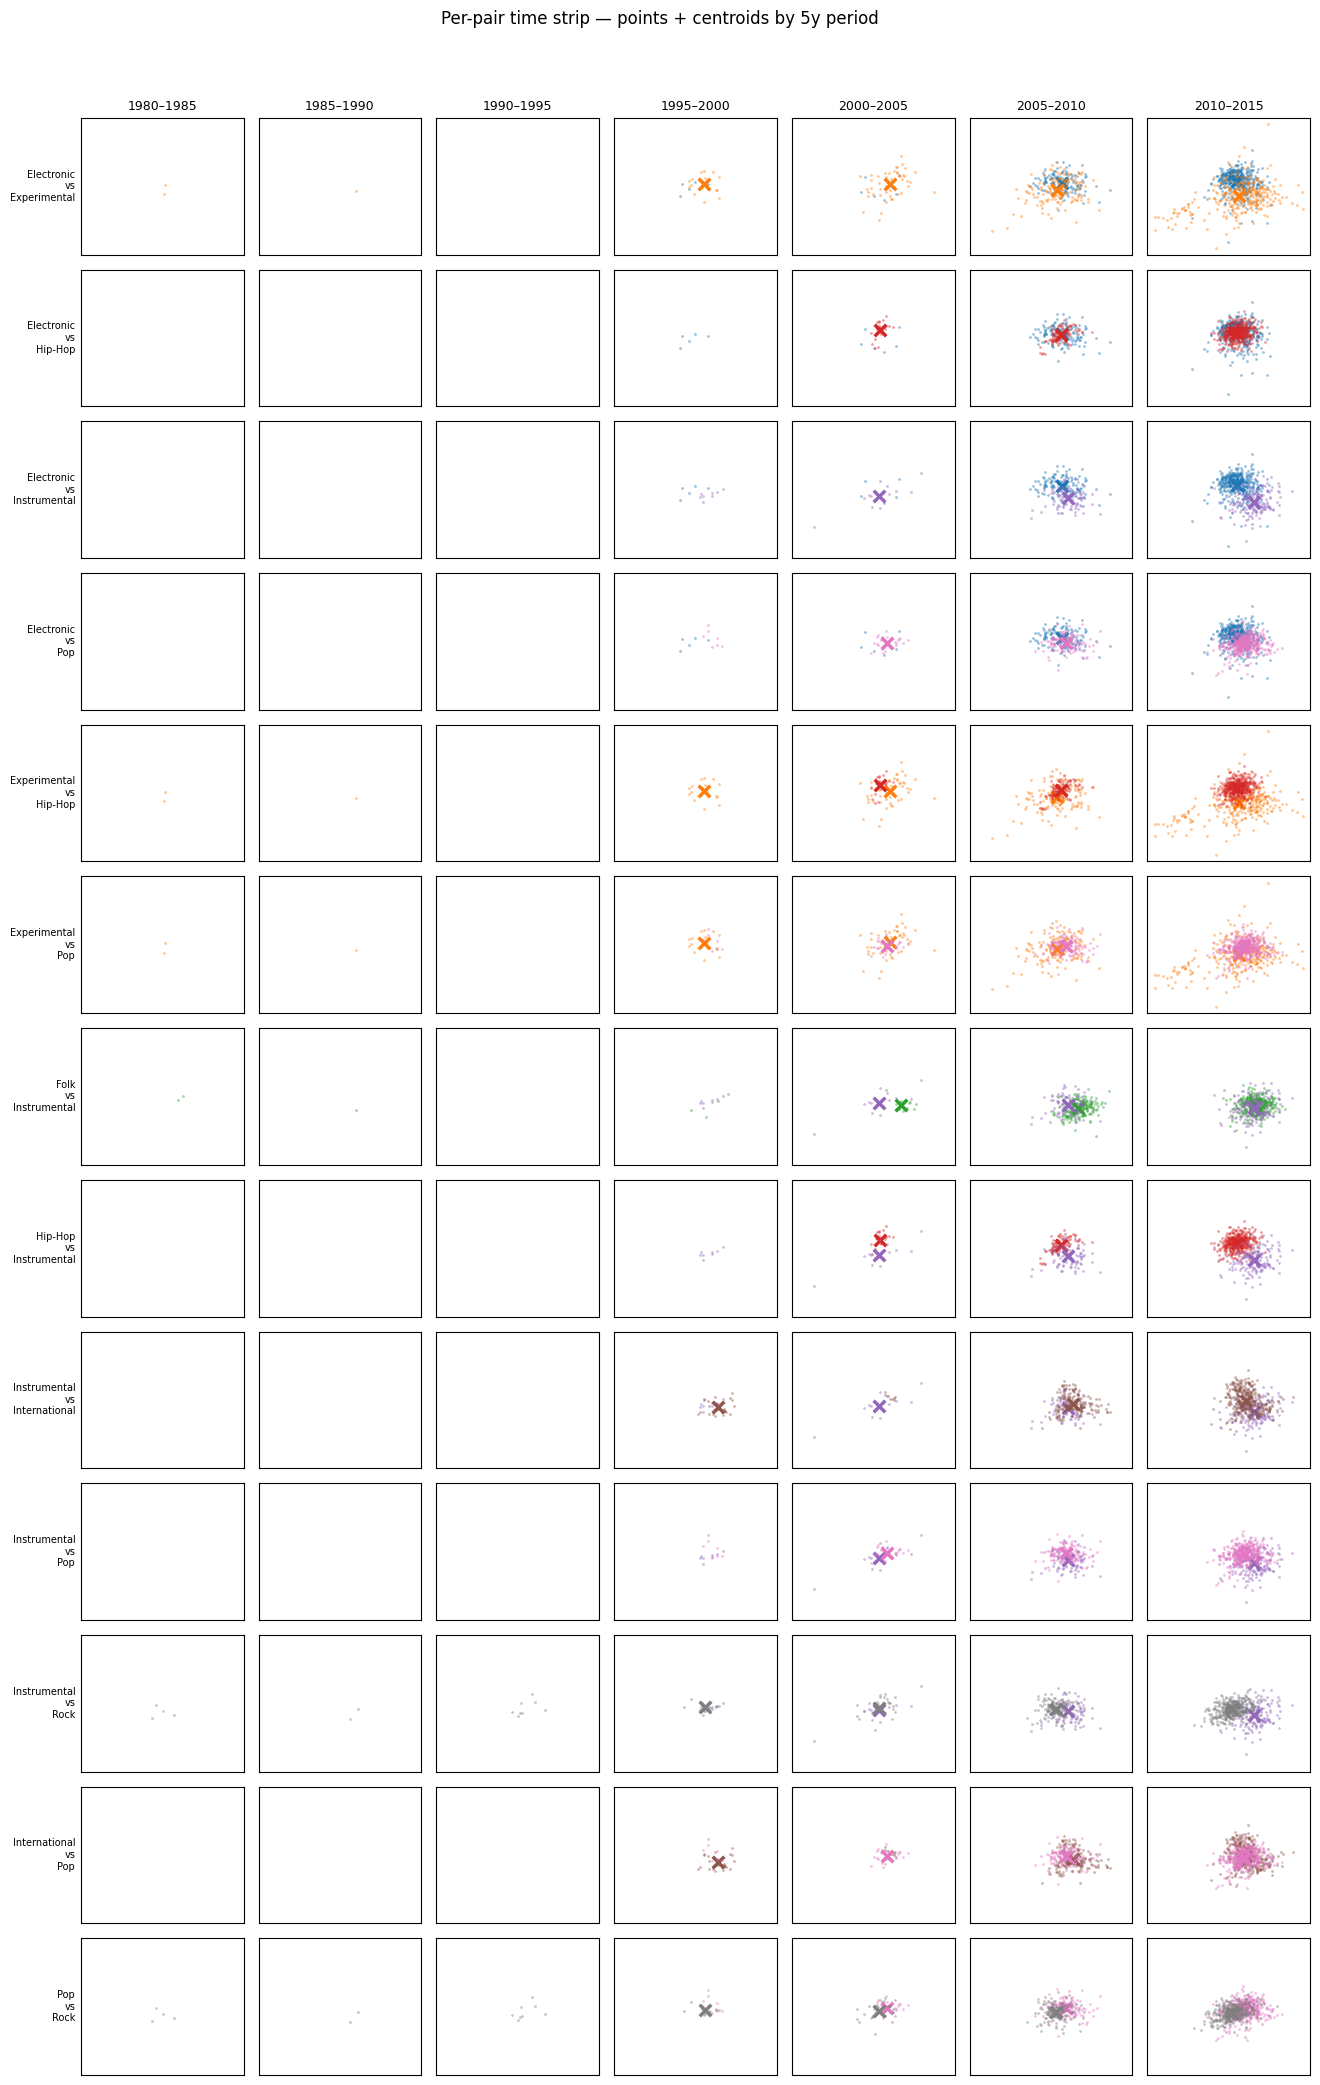

In [4]:
pairs = interesting_pairs(pair_result, threshold=0.3)
print(f'{len(pairs)} of 28 pairs qualify as interesting')
Visualizer.plot_pair_time_strip(pair_result, pairs=pairs)
plt.show()

### 3.3 Distance matrix preview

Raw per-period pair distances (rows = period start year, columns = `genre_a|genre_b`).

In [14]:
dist = pair_result.pair_distances
display(Markdown(f'Shape: **{dist.shape[0]} periods × {dist.shape[1]} pairs** — non-null cells per period:'))
display(dist.notna().sum(axis=1).to_frame('non_null_pairs'))
display(Markdown('First 6 pair columns:'))
display(dist.iloc[:, :6].round(2))

Shape: **7 periods × 28 pairs** — non-null cells per period:

,non_null_pairs
1980,0
1985,0
1990,0
1995,3
2000,15
2005,28
2010,28


First 6 pair columns:

,Electronic|Experimental,Electronic|Folk,Electronic|Hip-Hop,Electronic|Instrumental,Electronic|International,Electronic|Pop
1980,NaN,NaN,NaN,NaN,NaN,NaN
1985,NaN,NaN,NaN,NaN,NaN,NaN
1990,NaN,NaN,NaN,NaN,NaN,NaN
1995,NaN,NaN,NaN,NaN,NaN,NaN
2000,NaN,NaN,NaN,NaN,NaN,NaN
2005,5.27,12.44,0.84,7.54,7.43,3.66
2010,8.76,12.39,0.25,12.87,5.78,5.74


### 3.4 Top movers — concrete distance changes

Per genre pair, the first and last observed centroid distances, the absolute and relative change, and a direction label. Sorted by |relative change| so the biggest movers come first. Pulls live from `pair_result.pair_distances`, so the table reflects whichever subset you ran (small / medium / large).

In [ ]:
import pandas as pd

rows = []
for col in pair_result.pair_distances.columns:
    vals = pair_result.pair_distances[col].dropna()
    if len(vals) < 2 or vals.iloc[0] == 0:
        continue
    first, last = vals.iloc[0], vals.iloc[-1]
    abs_change = last - first
    rel_pct = abs_change / first * 100
    rows.append({
        'pair': col,
        'first_period': int(vals.index[0]),
        'last_period': int(vals.index[-1]),
        'n_periods': len(vals),
        'first_dist': round(first, 2),
        'last_dist': round(last, 2),
        'abs_change': round(abs_change, 2),
        'rel_change_pct': round(rel_pct, 1),
        'direction': 'converging' if last < first else ('diverging' if last > first else 'flat'),
    })

movers = (pd.DataFrame(rows)
          .sort_values('rel_change_pct', key=lambda s: s.abs(), ascending=False)
          .reset_index(drop=True))

display(Markdown(f'**{len(movers)} pairs** with \u22652 observed periods. Top 15 by |relative change|:'))
display(movers.head(15))

## 4. Summary of findings

### Section 1 — Per-decade PCA + k-means

The available data covers only **3 decades (1990, 2000, 2010)** at `min_samples=30`. The elbow curves for these decades are relatively smooth, so the optimal-k selection picks small `k` (typically 2-4) — consistent with the audio feature cloud being roughly unimodal in PCA-2D rather than cleanly separated. Genre color overlays show partial separation: Hip-Hop and Classical/Old-Time genres occupy distinct regions, but Rock / Pop / Electronic largely overlap.

### Section 2 — Title & genre exploration

These plots characterise the FMA *catalog* rather than music itself: genre shares shift mainly because the catalog grew unevenly across decades. The title-vocabulary plots show typical short, common words dominating; the duplicate-title rate captures naming-convention drift as much as stylistic similarity. Genre vocabulary overlap is highest for genre pairs that are stylistically adjacent (Rock-Pop) and lowest for stylistically distant pairs.

### Section 3 — Genre-pair PCA centroid distances (key findings)

**Setup**: Global PCA fit once on standardized audio features + cross-feature derivations. Centroid per `(period, genre)` cell with ≥10 tracks; Euclidean distance between centroids in PCA-2D.

**Variance captured**: PC1 12.3% + PC2 ~7% ≈ **19-20%** in both `small` and `large` subsets. Two dimensions capture the dominant axes of variation but distances should be interpreted as a *projection*, not full feature-space distances.

**Data coverage**:

| subset | tracks | genres | pairs | non-null cells per period (1980/85/90/95/2000/2005/2010) |
|---|---|---|---|---|
| `small` | 4 099 | 8 | 28 | 0 / 0 / 0 / 3 / 15 / 28 / 28 |
| `large` | 27 864 | 16 | 120 | 1 / 1 / 0 / 10 / 66 / 105 / 105 |

Pre-2000 is sparse in both — FMA's release-date metadata is concentrated post-2000. Findings below are read from 2005-2010 unless noted.

**Concrete movements** (from the actual distance matrix):

- **Hip-Hop vs. Electronic collapse**: `0.84 → 0.25` between 2005 and 2010 — a near-merger of their centroids in PCA-2D. Strong convergence signal.
- **Electronic vs. Instrumental diverge**: `7.54 → 12.87` over the same period — these are pulling apart.
- **Electronic vs. Experimental diverge**: `5.27 → 8.76`.
- **Electronic vs. International converge mildly**: `7.43 → 5.78`.
- **Electronic vs. Folk stable**: `12.44 → 12.39`.
- On `large`, **Old-Time / Historic drifts AWAY from most other genres** — the orange line consistently trends upward across anchor subplots. Plausibly reflects the FMA's older "historic" tracks being stylistically further from contemporary recordings as the catalog adds more recent music.
- **65 of 120 pairs (54%) qualify as "interesting"** on `large` (≥30% relative distance change between first and last available period).

**Caveats**:

1. **PCA-2D is a low-dimensional projection** of a ~500-dim feature space. A pair can move in 2D while staying constant in full-D, or vice versa.
2. **Distance changes mix two signals**: actual stylistic drift, *and* shifts in which tracks of a given genre got tagged in FMA. A genre whose membership composition changes (e.g. more lo-fi indie added under "Folk" in 2010) will show centroid movement that isn't purely about music style.
3. **Short series are noisy**: pairs with only 2-3 non-null periods can register large relative changes by chance. Treat single-jump trends with caution; consistent trends across multiple periods are stronger.
4. **Pre-2000 is largely missing**. The most confident claims here cover the **2005-2010** window only.

**Next reasonable steps** (not done in this notebook):

- Re-run section 3 with `subset='large'` to use 120 pairs / 16 genres instead of 28/8 (~22s runtime).
- Use full-feature-space distances (Mahalanobis or Euclidean on standardized features) in addition to PCA-2D, to confirm whether movements are projection artifacts.
- Stratify by `genre_top` membership stability — count how many tracks per genre change across periods to disentangle stylistic drift from tagging drift.

## 5. Failed stretch goal — lyrics scraping

As a stretch goal we tried to scrape song lyrics from the **Genius API** (via the `lyricsgenius` library; code lives on the `feature/lyrics` branch in `lyrics.py`) so we could add lexical analyses of the actual lyrics — vocabulary-by-decade, sentiment, topic modeling. After filtering FMA's catalog to lyric-bearing genres (Rock, Hip-Hop, Folk, Pop, Country, Soul-RnB, Blues — 22 713 tracks) and running a parallel scraper overnight, we only ended up with **661 cached lyrics (~3% of attempts)**. Two issues stacked: (1) FMA is mostly Creative-Commons indie that simply isn't in Genius's commercial catalog ( 22% legitimately `not_found`), and (2) over hours of running, Genius's Cloudflare protection started returning HTTP 429 ("Too Many Requests") and **~75% of the run errored** despite a conservative `-N 2 --sleep 0.5` pacing. The 661 lyrics we did get are almost all English (646 `en`, plus small counts of `pt`, `fr`, `de`, `id`, `ja`, `af`, `ca`).